In [7]:
import pandas as pd
df = pd.read_csv("C:\\Users\\lenovo\\Downloads\\StudentsPerformance.csv")

In [8]:
df.head(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [9]:
df.shape

(1000, 8)

# 1.Descriptive Statistics

In [10]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


# 2..Comparison of all other attributes with respect to Math Marks

In [12]:
#  correlation
correlations = df.corr()['math score']

C:\Users\lenovo\AppData\Local\Temp\ipykernel_11888\2740026844.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlations = df.corr()['math score']


In [13]:
correlations

math score       1.000000
reading score    0.817580
writing score    0.802642
Name: math score, dtype: float64

# 3.Comparison of all other attributes with respect to Reading Marks

In [14]:
correlations = df.corr()['reading score']

C:\Users\lenovo\AppData\Local\Temp\ipykernel_11888\1264031545.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlations = df.corr()['reading score']


In [15]:
correlations

math score       0.817580
reading score    1.000000
writing score    0.954598
Name: reading score, dtype: float64

# 5.CHECK the effect of test preparation course on scores.



* Convert test_preparation_course into numerical values (0 for "none", 1 for "completed")

In [16]:
df['test_preparation_course_encoded'] = df['test preparation course'].apply(lambda x: 1 if x == 'completed' else 0)

In [17]:
df['test_preparation_course_encoded']

0      0
1      1
2      0
3      0
4      0
      ..
995    1
996    0
997    1
998    1
999    0
Name: test_preparation_course_encoded, Length: 1000, dtype: int64

* calculate the correlation

In [18]:
correlation_math = df['test_preparation_course_encoded'].corr(df['math score'])
correlation_reading = df['test_preparation_course_encoded'].corr(df['reading score'])
correlation_writing = df['test_preparation_course_encoded'].corr(df['writing score'])

In [19]:
correlation_math 

0.17770246930439462

In [20]:
correlation_reading

0.24178043354875134

In [21]:
correlation_writing

0.312946284485956

# 5.Visualizing the number of male and female in the data set


<Axes: >

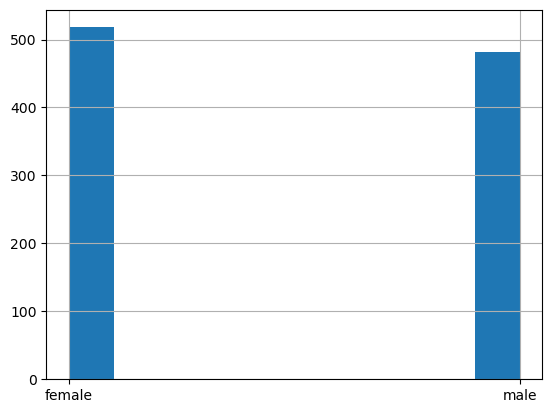

In [22]:
df["gender"].hist()

In [23]:
gender_counts = df["gender"].value_counts()

In [24]:
print("males are :" , gender_counts["male"])

males are : 482


In [25]:
print("females are : " ,gender_counts["female"])

females are :  518


# 6..Visualizing the different groups in the data set

<Axes: >

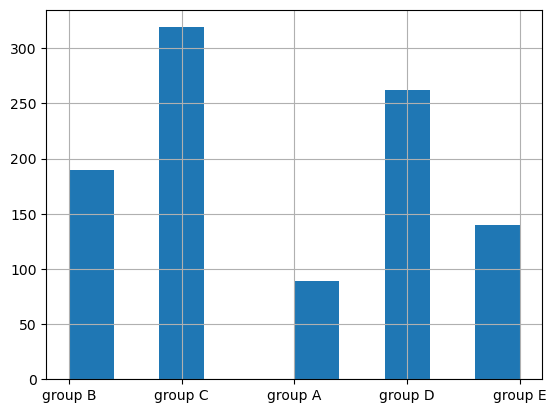

In [26]:
df["race/ethnicity"].hist()

# 7. Visualizing the number of male and female in the data set

<Axes: >

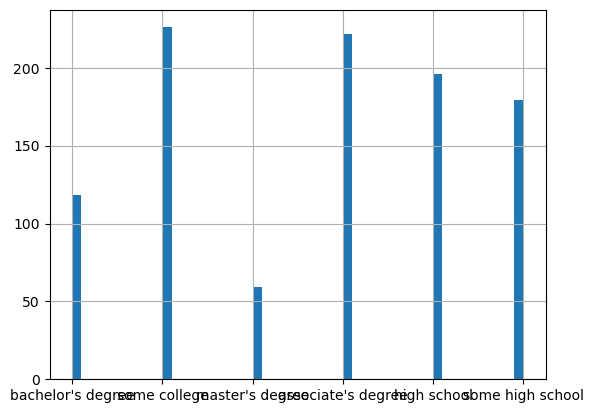

In [27]:
df["parental level of education"].hist(bins = 50)

# 8..Visualizing Maths score

<Axes: >

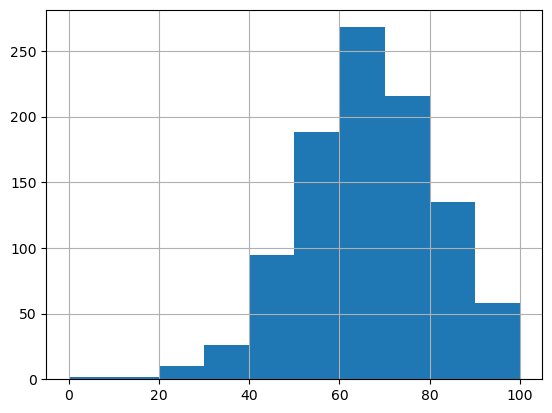

In [28]:
df["math score"].hist()

# 9.Computing the total score for each student

In [29]:
# cmputing the total score of each student 
df["total score"] = df["math score"]+df["reading score"]+df["writing score"]

In [30]:
df.head(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,test_preparation_course_encoded,total score
0,female,group B,bachelor's degree,standard,none,72,72,74,0,218
1,female,group C,some college,standard,completed,69,90,88,1,247
2,female,group B,master's degree,standard,none,90,95,93,0,278
3,male,group A,associate's degree,free/reduced,none,47,57,44,0,148
4,male,group C,some college,standard,none,76,78,75,0,229


# 10.Computing percentage for each of the students

In [31]:
df["perc"]  = (df["total score"]/300)*100

In [32]:
df.head(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,test_preparation_course_encoded,total score,perc
0,female,group B,bachelor's degree,standard,none,72,72,74,0,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,1,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,0,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,0,148,49.333333
4,male,group C,some college,standard,none,76,78,75,0,229,76.333333


# Performance the model

## logistic regression


In [33]:
# Define the pass/fail threshold
pass_threshold = 60

# Create 'pass_or_fail' column based on the threshold
df['pass_or_fail'] = df['perc'].apply(lambda x: 1 if x >= pass_threshold else 0)
df['pass_or_fail']

0      1
1      1
2      1
3      0
4      1
      ..
995    1
996    0
997    1
998    1
999    1
Name: pass_or_fail, Length: 1000, dtype: int64

In [34]:
# Define features and target
X = df[['perc',"test_preparation_course_encoded"]]
X


,perc,test_preparation_course_encoded
0,72.666667,0
1,82.333333,1
2,92.666667,0
3,49.333333,0
4,76.333333,0
...,...,...
995,94.000000,1
996,57.333333,0
997,65.000000,1
998,74.333333,1


In [35]:
y = df['pass_or_fail']
y

0      1
1      1
2      1
3      0
4      1
      ..
995    1
996    0
997    1
998    1
999    1
Name: pass_or_fail, Length: 1000, dtype: int64

In [36]:
# Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [37]:
# Initialize and train the logistic regression model
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train, y_train)



LogisticRegression()

In [38]:

# Predict on the test set
y_pred = model.predict(X_test)


In [42]:
# Evaluate the model
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)


In [43]:
accuracy

1.0

In [44]:
report

'              precision    recall  f1-score   support\n\n           0       1.00      1.00      1.00        62\n           1       1.00      1.00      1.00       138\n\n    accuracy                           1.00       200\n   macro avg       1.00      1.00      1.00       200\nweighted avg       1.00      1.00      1.00       200\n'

#  confusion matrix

In [45]:
from sklearn.metrics import confusion_matrix

In [46]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[ 62,   0],
       [  0, 138]], dtype=int64)

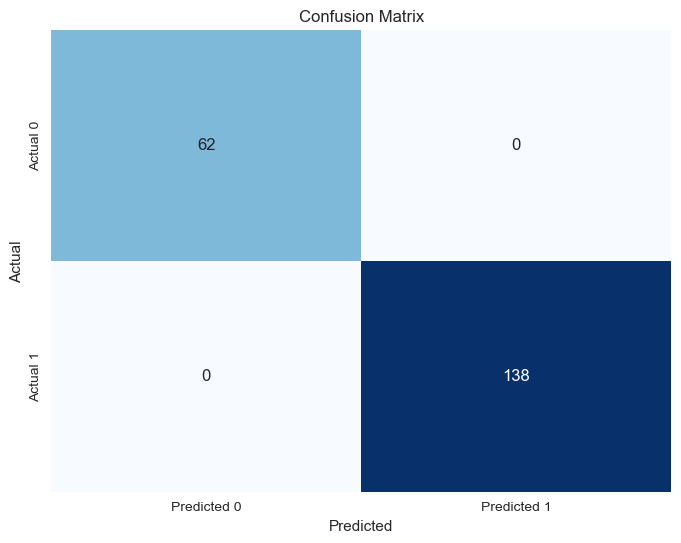

In [49]:
# Create a heatmap of the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()
